In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [5]:
file_path = "/content/merged_battleground.csv"

df = pd.read_csv(file_path)
df.head()

,No.,Time,Source,Destination,Protocol,Length,Info
0,1,2022-10-05 15:59:09.860208,10.215.173.1,10.215.173.2,DNS,75.0,Standard query 0xa12e A android.crashsight.wet...
1,2,2022-10-05 15:59:09.902414,10.215.173.1,150.109.248.116,TCP,60.0,49290 > 17500 [SYN] Seq=0 Win=65535 Len=0 MS...
2,3,2022-10-05 15:59:09.974104,10.215.173.2,10.215.173.1,DNS,430.0,Standard query response 0xa12e A android.crash...
3,4,2022-10-05 15:59:09.978576,10.215.173.1,150.109.29.250,TCP,60.0,43184 > 443 [SYN] Seq=0 Win=65535 Len=0 MSS=...
4,5,2022-10-05 15:59:09.998480,150.109.248.116,10.215.173.1,TCP,48.0,"17500 > 49290 [SYN, ACK] Seq=0 Ack=1 Win=204..."


This cell checks the dataset’s size, column names, data types, and non-empty values. These checks help us understand what information is available before cleaning or training a model.

In [6]:
print("Dataset shape (rows, columns):")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape (rows, columns):
(1604706, 7)

Column names:
['No.', 'Time', 'Source', 'Destination', 'Protocol', 'Length', 'Info']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1604706 entries, 0 to 1604705
Data columns (total 7 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   No.          1604706 non-null  int64  
 1   Time         1604706 non-null  object 
 2   Source       1604706 non-null  object 
 3   Destination  1604705 non-null  object 
 4   Protocol     1604705 non-null  object 
 5   Length       1604705 non-null  float64
 6   Info         1604329 non-null  object 
dtypes: float64(1), int64(1), object(5)
memory usage: 85.7+ MB


This cell checks for missing values in each column and counts duplicate rows. We’ll use these results to decide what needs cleaning before training the models

In [7]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

Missing values in each column:
No.              0
Time             0
Source           0
Destination      1
Protocol         1
Length           1
Info           377
dtype: int64

Number of duplicate rows:
0


This cell removes rows without a known protocol label and removes duplicate records. The protocol label is the answer the model will learn to predict, so rows without it cannot be used for training.

In [8]:
rows_before = len(df)

df = df.dropna(subset=["Protocol"])
df = df.drop_duplicates()

print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", len(df))
print("Rows removed:", rows_before - len(df))

Rows before cleaning: 1604706
Rows after cleaning: 1604705
Rows removed: 1


This cell counts the records for each network protocol. The counts show which protocol classes the model will learn and whether some classes have far fewer examples than others

In [9]:
print("Number of protocol classes:", df["Protocol"].nunique())
print("\nRecords for each protocol:")
print(df["Protocol"].value_counts())

Number of protocol classes: 23

Records for each protocol:
Protocol
UDP              1542508
TCP                28706
DB-LSP             19938
TLSv1.2             5938
SSL                 3385
DNS                 1992
RTCP                1414
TLSv1.3              583
HTTP                  73
R-GOOSE               35
DCP-PFT               27
CLTP                  24
THRIFT                24
WireGuard             16
DCP-AF                16
Pathport              11
Elasticsearch          4
HCrt                   2
MANOLITO               2
KINK                   2
ATH                    2
0x0000                 2
MPEG TS                1
Name: count, dtype: int64


These charts show how often each protocol appears and how packet lengths are distributed. They help us understand the dataset before training the models

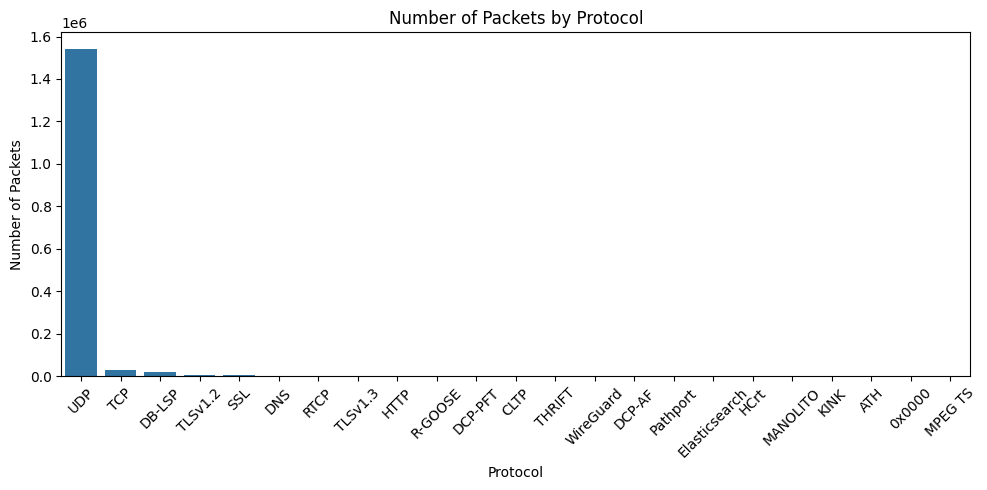

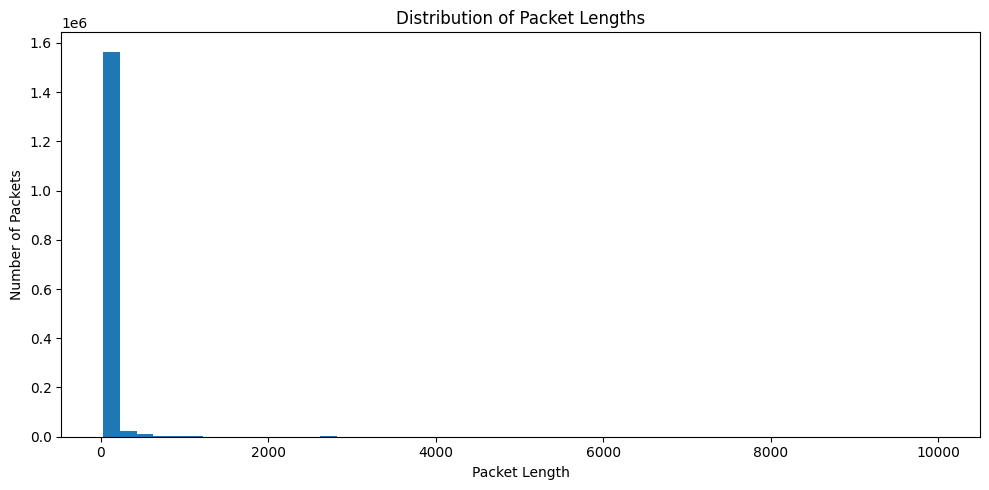

In [10]:
# Show the number of packets for each protocol.
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df,
    x="Protocol",
    order=df["Protocol"].value_counts().index
)
plt.title("Number of Packets by Protocol")
plt.xlabel("Protocol")
plt.ylabel("Number of Packets")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Show the distribution of packet lengths.
plt.figure(figsize=(10, 5))
plt.hist(df["Length"].dropna(), bins=50)
plt.title("Distribution of Packet Lengths")
plt.xlabel("Packet Length")
plt.ylabel("Number of Packets")
plt.tight_layout()
plt.show()

This cell limits the cleaned dataset to 100,000 randomly selected rows if it is larger. A fixed random seed makes the selection reproducible.

In [11]:
if len(df) > 100_000:
    df = df.sample(n=100_000, random_state=42).copy()

print("Rows for this project:", len(df))

Rows for this project: 100000


This cell converts packet time into hour, minute, and second features, and ensures packet length is numeric. We’ll use these packet characteristics to predict the protocol.

In [12]:
df["Time"] = pd.to_datetime(df["Time"], errors="coerce")
df["Length"] = pd.to_numeric(df["Length"], errors="coerce")

df["Hour"] = df["Time"].dt.hour
df["Minute"] = df["Time"].dt.minute
df["Second"] = df["Time"].dt.second

df[["Time", "Length", "Hour", "Minute", "Second", "Protocol"]].head()

,Time,Length,Hour,Minute,Second,Protocol
850067,2022-10-06 15:58:35.013573,79.0,15,58,35,UDP
919078,2022-10-06 16:14:37.485798,37.0,16,14,37,UDP
1567535,2022-10-07 14:14:28.963675,49.0,14,14,28,UDP
1394185,2022-10-07 13:28:18.548424,58.0,13,28,18,UDP
882975,2022-10-06 16:06:12.723121,82.0,16,6,12,UDP


This cell selects packet length and time information as the model’s input features. It selects Protocol as the target the model will learn to predict, and fills missing feature values with zero.

In [13]:
feature_columns = ["Length", "Hour", "Minute", "Second"]

X = df[feature_columns].fillna(0)
y = df["Protocol"]

print("Input features:")
display(X.head())

print("\nTarget labels:")
display(y.head())

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Input features:


,Length,Hour,Minute,Second
850067,79.0,15,58,35
919078,37.0,16,14,37
1567535,49.0,14,14,28
1394185,58.0,13,28,18
882975,82.0,16,6,12



Target labels:


,Protocol
850067,UDP
919078,UDP
1567535,UDP
1394185,UDP
882975,UDP



Feature shape: (100000, 4)
Target shape: (100000,)


This cell converts protocol names into numeric labels because the machine learning models work with numbers. It then divides the data into training records and test records, keeping the protocol proportions similar in both groups.

This cell scales the input features for Logistic Regression and KNN, which work better when features are on a similar scale. The scaler is fitted using training data only, then applied to the test data

In [17]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Scaled training data shape: (79998, 4)
Scaled testing data shape: (20000, 4)


This cell trains a Logistic Regression classifier using the scaled training data, then predicts protocol labels for the test data

In [18]:
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train_scaled, y_train)

y_pred_lr = logistic_model.predict(X_test_scaled)

print("Logistic Regression model trained.")

Logistic Regression model trained.


This cell measures Logistic Regression performance on the test data. Accuracy gives the overall percentage of correct predictions, while the classification report shows precision, recall, and F1-score for each protocol

In [19]:
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print(f"Logistic Regression accuracy: {accuracy_lr:.2%}")
print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred_lr,
        labels=range(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

Logistic Regression accuracy: 96.36%

Classification report:
              precision    recall  f1-score   support

        CLTP       0.00      0.00      0.00         0
      DB-LSP       0.44      0.10      0.17       254
     DCP-PFT       0.00      0.00      0.00         1
         DNS       0.00      0.00      0.00        31
        HTTP       0.00      0.00      0.00         1
     R-GOOSE       0.00      0.00      0.00         1
        RTCP       0.00      0.00      0.00        17
         SSL       0.00      0.00      0.00        43
         TCP       0.00      0.00      0.00       369
      THRIFT       0.00      0.00      0.00         0
     TLSv1.2       0.89      0.59      0.71        79
     TLSv1.3       0.00      0.00      0.00         6
         UDP       0.97      1.00      0.98     19198
   WireGuard       0.00      0.00      0.00         0

    accuracy                           0.96     20000
   macro avg       0.16      0.12      0.13     20000
weighted avg       

In [20]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)
accuracy_knn = accuracy_score(y_test, y_pred_knn)

print(f"KNN accuracy: {accuracy_knn:.2%}")

KNN accuracy: 96.73%


In [21]:
tree_model = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)
tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)
accuracy_tree = accuracy_score(y_test, y_pred_tree)

print(f"Decision Tree accuracy: {accuracy_tree:.2%}")

Decision Tree accuracy: 97.44%


In [22]:
forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
forest_model.fit(X_train, y_train)

y_pred_forest = forest_model.predict(X_test)
accuracy_forest = accuracy_score(y_test, y_pred_forest)

print(f"Random Forest accuracy: {accuracy_forest:.2%}")

Random Forest accuracy: 98.02%


,Model,Accuracy (%)
0,Logistic Regression,96.355
1,KNN,96.735
2,Decision Tree,97.440
3,Random Forest,98.015


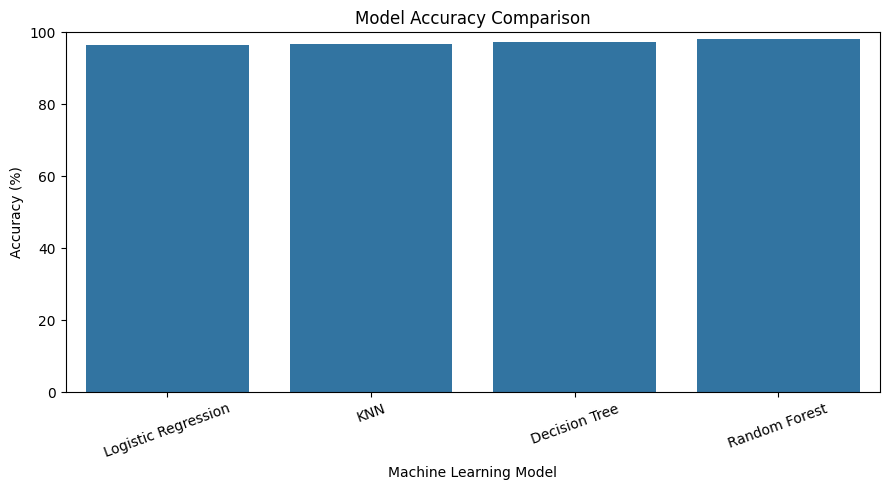

In [23]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_lr,
        accuracy_knn,
        accuracy_tree,
        accuracy_forest
    ]
})

results["Accuracy (%)"] = results["Accuracy"] * 100

display(results[["Model", "Accuracy (%)"]])

plt.figure(figsize=(9, 5))
sns.barplot(data=results, x="Model", y="Accuracy (%)")
plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


This cell selects the model with the highest test accuracy, then shows its classification report and confusion matrix. The report summarizes performance for each protocol; the confusion matrix shows correct and incorrect predictions.

Best model: Random Forest
Test accuracy: 98.02%

Classification report:
              precision    recall  f1-score   support

        CLTP       0.00      0.00      0.00         0
      DB-LSP       0.73      0.57      0.64       254
     DCP-PFT       0.00      0.00      0.00         1
         DNS       0.80      0.13      0.22        31
        HTTP       0.00      0.00      0.00         1
     R-GOOSE       0.00      0.00      0.00         1
        RTCP       0.25      0.06      0.10        17
         SSL       0.88      0.35      0.50        43
         TCP       0.79      0.82      0.81       369
      THRIFT       0.00      0.00      0.00         0
     TLSv1.2       0.85      0.78      0.82        79
     TLSv1.3       0.00      0.00      0.00         6
         UDP       0.99      0.99      0.99     19198
   WireGuard       0.00      0.00      0.00         0

    accuracy                           0.98     20000
   macro avg       0.38      0.26      0.29     20000
weighted

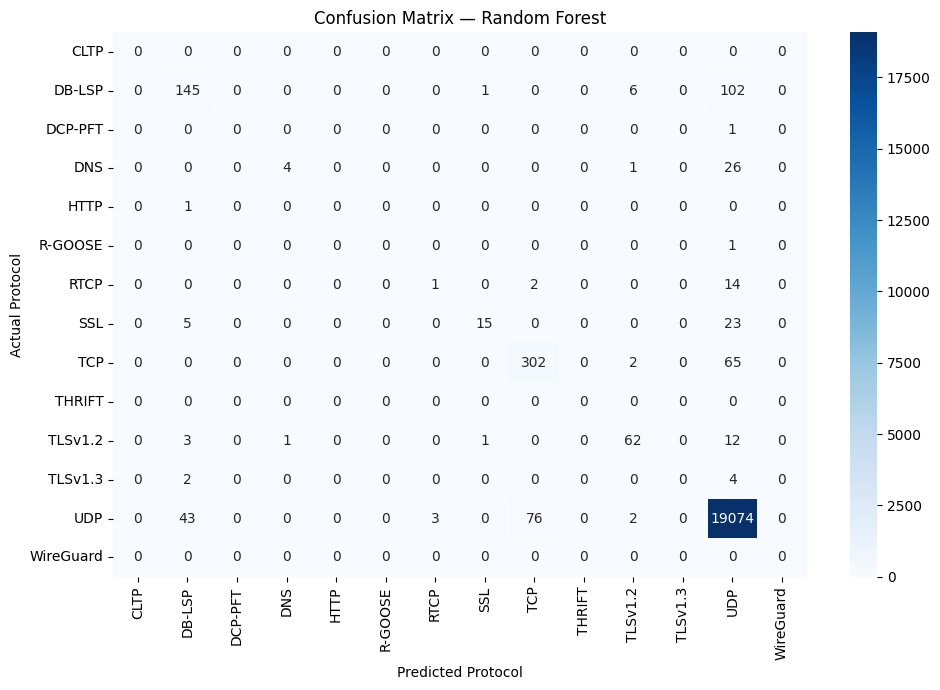

In [24]:
model_predictions = {
    "Logistic Regression": (accuracy_lr, y_pred_lr),
    "KNN": (accuracy_knn, y_pred_knn),
    "Decision Tree": (accuracy_tree, y_pred_tree),
    "Random Forest": (accuracy_forest, y_pred_forest)
}

best_model_name = max(
    model_predictions,
    key=lambda name: model_predictions[name][0]
)
best_accuracy, best_predictions = model_predictions[best_model_name]

print(f"Best model: {best_model_name}")
print(f"Test accuracy: {best_accuracy:.2%}")

print("\nClassification report:")
print(
    classification_report(
        y_test,
        best_predictions,
        labels=range(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

confusion = confusion_matrix(
    y_test,
    best_predictions,
    labels=range(len(label_encoder.classes_))
)

plt.figure(figsize=(10, 7))
sns.heatmap(
    confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.xlabel("Predicted Protocol")
plt.ylabel("Actual Protocol")
plt.tight_layout()
plt.show()

This cell uses the best-performing model to predict the protocol for one example packet. The example packet is represented using the same four features used during training

In [25]:
example_packet = pd.DataFrame({
    "Length": [75],
    "Hour": [15],
    "Minute": [59],
    "Second": [9]
})

best_models = {
    "Logistic Regression": logistic_model,
    "KNN": knn_model,
    "Decision Tree": tree_model,
    "Random Forest": forest_model
}

best_model = best_models[best_model_name]

if best_model_name in ["Logistic Regression", "KNN"]:
    example_input = scaler.transform(example_packet)
else:
    example_input = example_packet

predicted_label = best_model.predict(example_input)
predicted_protocol = label_encoder.inverse_transform(predicted_label)

print("Example packet:")
display(example_packet)
print("Predicted protocol:", predicted_protocol[0])

Example packet:


,Length,Hour,Minute,Second
0,75,15,59,9


Predicted protocol: UDP


In [27]:
print("PROJECT CONCLUSION")
print(
    "Four machine learning models were trained to predict "
    "network protocols using packet length and time features."
)
print(
    f"The best-performing model was {best_model_name}, "
    f"with a test accuracy of {best_accuracy:.2%}."
)
print(
    "The confusion matrix and classification report were used "
    "to review the model's predictions for each protocol."
)

PROJECT CONCLUSION
Four machine learning models were trained to predict network protocols using packet length and time features.
The best-performing model was Random Forest, with a test accuracy of 98.02%.
The confusion matrix and classification report were used to review the model's predictions for each protocol.


,Feature,Importance
0,Length,0.557278
3,Second,0.179789
2,Minute,0.176031
1,Hour,0.086902


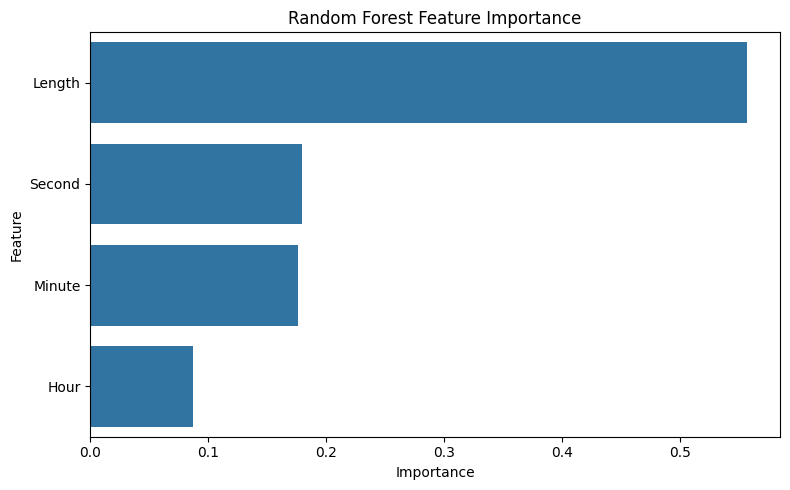

In [28]:
feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": forest_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

display(feature_importance)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

This cell displays the first few levels of the trained Decision Tree. Limiting the displayed depth makes its decision rules easier to read

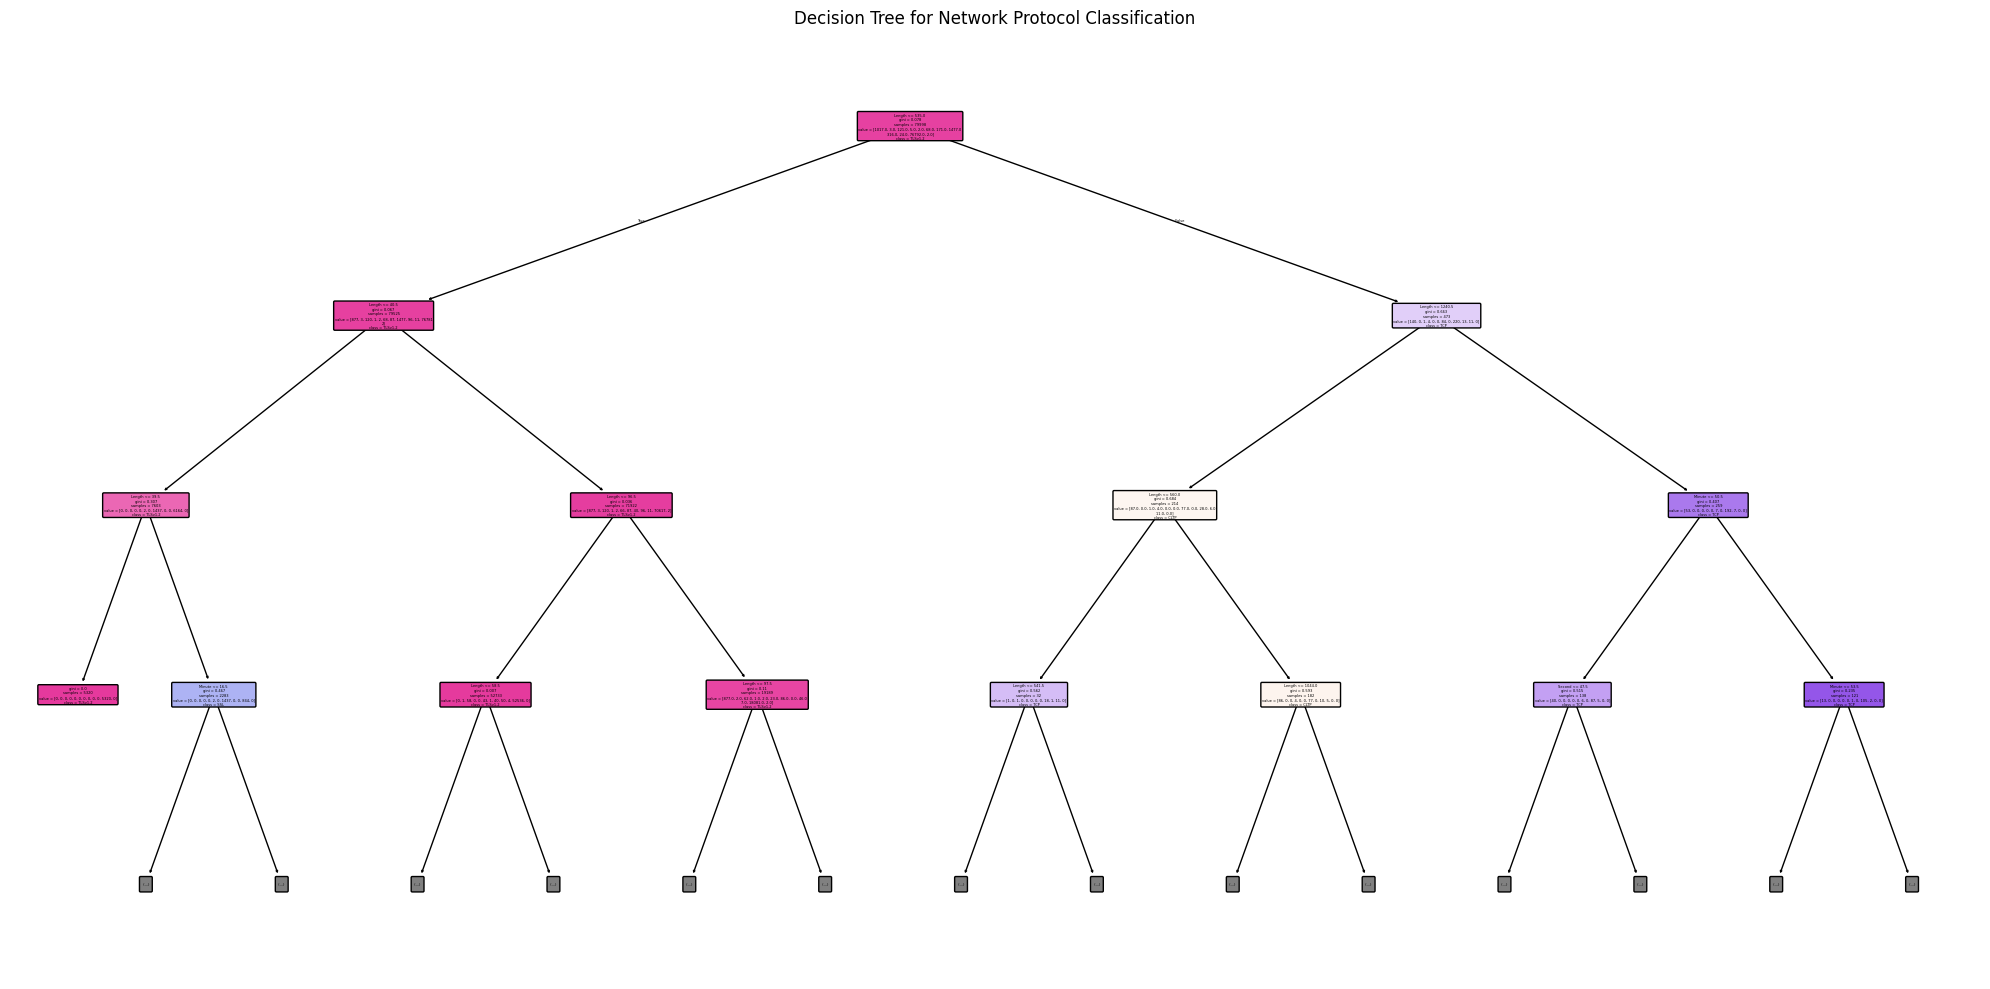

In [29]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(
    tree_model,
    feature_names=feature_columns,
    class_names=label_encoder.classes_,
    filled=True,
    max_depth=3,
    rounded=True
)
plt.title("Decision Tree for Network Protocol Classification")
plt.tight_layout()
plt.show()